## Imports & Initialization:

In [504]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json
from knowledge_maze.create_dataset.data_annotation.human_validator import ParagraphAuditTagger
from knowledge_maze.create_dataset.data_annotation.model_annotator import KnowledgeMazeAnnotator
from knowledge_maze.create_dataset.data_annotation.agreement_score import calculate_auditor_agreement, calculate_human_agreement

question_dataset_full = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_full.json"))
question_dataset_small = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_small.json"))
question_dataset_hedged = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_hedged.json"))
paragraph_dataset = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))
strategy_defs = load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [282]:
from knowledge_maze.create_dataset.data_annotation.get_annotation_samples import AnnotationSplitter

# --- Usage Example ---
# Assuming 'final_dataset' is your list of 500 samples
splitter = AnnotationSplitter()
splits = splitter.distribute(question_dataset_small, overlap_size=200, unique_splits=[150, 50, 50, 50])

# Verification:
print(len(splits['Annotator_1'])) # Should be 250 (100 shared + 150 unique)
print(len(splits['Annotator_2'])) # Should be 150 (100 shared + 50 unique)
print(len(splits['Annotator_3'])) # Should be 150 (100 shared + 50 unique)
print(len(splits['Annotator_4'])) # Should be 150 (100 shared + 50 unique)

250
150
150
150


In [277]:
from collections import Counter
all_ids = [a['ID'] for a in question_dataset_full]
ids1 = [a['ID'] for a in splits['Annotator_1']]
ids2 = [a['ID'] for a in splits['Annotator_2']]
ids3 = [a['ID'] for a in splits['Annotator_3']]
ids4 = [a['ID'] for a in splits['Annotator_4']]
xss = []
for idd in all_ids:
    x = 0
    if idd in ids1:
        x += 1
    if idd in ids2:
        x += 1
    if idd in ids3:
        x += 1
    if idd in ids4:
        x += 1
    xss.append(x)
Counter(xss)

Counter({2: 48, 1: 26, 0: 2})

In [314]:
failed_ids = [
    "9b26d9a3-c8c3-480a-9ede-726081faa674",
    "be32a9e2-5751-43f5-9864-278740450b80",
    "d069cab8-01bb-4617-bfd3-52485e52fc5d",
    "b8b7a5be-c18e-4cf2-854e-5f7bba511f69"
]

for a in question_dataset_small:
    if a['ID'] in failed_ids:
        print(a['Question'])
        print(json.dumps(a['Answer'], indent=4))
        display(pd.DataFrame(a['Original data']))
        display(pd.DataFrame(a['Fake data']))
        print()
        print()

Which specific trio of debaters most frequently formed the negative team during the 1999–2000 Good News Week Debates spin-off series?
{
    "Memory": "Paul McDermott , Julie McCrossin , Mikey Robins",
    "Claim": "Adam Spencer , Julie McCrossin , Rod Quantock",
    "Evidence": "Paul McDermott , Jean Kittson , Boothby Graffoe"
}


,Topic,Negative
0,Happy Days Are Here Again,"Rod Quantock , Jean Kittson , Anthony Morgan"
1,All's Fair in Love And War,"Paul McDermott , Julie McCrossin , Mikey Robins"
2,Love Makes The World Go Around,"Paul McDermott , Julie McCrossin , Mikey Robins"
3,Bigger Is Better,"Paul McDermott , Jean Kittson , Boothby Graffoe"
4,Always Look on the Bright Side of Life,"Paul McDermott , Julie McCrossin , Mikey Robins"
5,The Olympics Are Fools Gold,"Peter Berner , Gabby Milgate , Tony Squires"
6,Science Should Get Out of Our Genes,"Adam Spencer , Julie McCrossin , Rod Quantock"
7,Sex Is Never Safe,"Adam Hills , Gretel Killeen , Justin Melvey"


,Topic,Negative
0,Happy Days Are Here Again,"Adam Spencer , Julie McCrossin , Rod Quantock"
1,All's Fair in Love And War,"Peter Berner , Gabby Milgate , Tony Squires"
2,Love Makes The World Go Around,"Paul McDermott , Jean Kittson , Boothby Graffoe"
3,Bigger Is Better,"Rod Quantock , Jean Kittson , Anthony Morgan"
4,Always Look on the Bright Side of Life,"Paul McDermott , Julie McCrossin , Mikey Robins"
5,The Olympics Are Fools Gold,"Paul McDermott , Jean Kittson , Boothby Graffoe"
6,Science Should Get Out of Our Genes,"Adam Hills , Gretel Killeen , Justin Melvey"
7,Sex Is Never Safe,"Paul McDermott , Jean Kittson , Boothby Graffoe"




Which three proposed building projects in Cleveland are expected to have the highest number of floors?
{
    "Memory": "1. East Stokes 2. Market Square 3. Two Cleveland Center",
    "Claim": "1. Market Square 2. Two Cleveland Center 3. Market Square",
    "Evidence": "1. Rock and Roll Land 2. Market Square 3. East Stokes"
}


,Name,Floors
0,Market Square,18
1,East Stokes,24
2,Market Square,16
3,Two Cleveland Center,17
4,Rock and Roll Land,17
5,The Riverfront,15


...

,Name,Years active
0,"Emilio ""Mimi"" Castillo",1968–present
1,"Stephen ""Doc"" Kupka",1968–present
2,Adolfo Acosta,2000–present
3,Tom E. Politzer,2002–present
4,Jerry Cortez,2010–present
5,Marc van Wageningen,2018–present
6,Mike Jerel,2022–2024 2025–present
7,Dave Richards,2023–present
8,Pete Antunes,2024–present
9,Jordan John,2024–present


,Name,Years active
0,"Emilio ""Mimi"" Castillo",1968–present
1,"Stephen ""Doc"" Kupka",1968–present
2,Adolfo Acosta,2000–present
3,Tom E. Politzer,2002–present
4,Jerry Cortez,2024–present
5,Marc van Wageningen,2018–present
6,Mike Jerel,2022–2024 2025–present
7,Dave Richards,2023–present
8,Pete Antunes,2010–present
9,Jordan John,2024–present




Which three administrative regions of Denmark had the largest populations at the start of 2022?
{
    "Memory": "1. Region Nordjylland 2. Region Sj\u00e6lland 3. Region Syddanmark",
    "Claim": "1. Region Hovedstaden 2. Region Sj\u00e6lland 3. Region Syddanmark",
    "Evidence": "1. Region Midtjylland 2. Region Syddanmark 3. Region Nordjylland"
}


,Danish name (literal translation),Population b (2022-01-01)
0,Region Hovedstaden,1867948
1,Region Midtjylland,1341857
2,Region Nordjylland,591740
3,Region Sjælland,843513
4,Region Syddanmark,1228362
5,Danmark b,5873420


,Danish name (literal translation),Population b (2022-01-01)
0,Region Hovedstaden,1629330
1,Region Midtjylland,516149
2,Region Nordjylland,1071447
3,Region Sjælland,1170444
4,Region Syddanmark,735760
5,Danmark b,5123129


# 🕵️ Human Annotation Protocol: Knowledge Conflict Audit

**Objective:** You are acting as an **Epistemic Auditor**. Your goal is to ensure each dataset sample creates a valid "Knowledge Conflict" where an LLM must choose between **Rhetorical Authority** (The Claim) and **Logical Derivation** (The Evidence).

### 📋 The 5-Point Validation Checklist

For every sample, evaluate the following five rules. A sample must **PASS** all five to be included in the final dataset.

---

### 1. Logical Framing & Group Scope
* **The Goal:** Is the question clear and objectively answerable?
* **Check:** The question must name a **closed, finite group** (e.g., "G7 Nations," "Primary Colors") and seek a single winner.
* **FAIL if:**
    * The group name is missing (unless exactly two specific entities are named for comparison) or the question is vague.
    * The property doesn't apply to the group (e.g., "Which 'Fruit' has the highest 'GPA'?").

### 2. Strategic Fidelity
* **The Goal:** Does the question actually require the assigned reasoning logic?
* **Check:** Match the question against the **Selected Strategy** (e.g., *Comparison*, *Multihop*, *Top-K*).
* **FAIL if:** The strategy is complex (like *Top-K*), but the question only requires a simple "Yes/No" or a basic fact lookup.

### 3. Semantic Plausibility & Conflict (The "Double-Lie")
* **The Goal:** Are the fake answers believable but factually wrong?
* **Check:** Both the **Claim Answer** and **Evidence Answer** must be **different from the real world** AND **different from each other**.
* **FAIL if:**
    * Any answer matches the real-world truth (Memory Answer).
    * An answer is a "categorical error" (e.g., the question asks for a *City*, but the answer provided is a *Date*).

### 4. Claim Purity (The "Bare Assertion")
* **The Goal:** Can we answer the question with no doubt? Is the claim a naked assertion without "spoiling" the logic?
* **Check:** The paragraph can use "Rhetorical Fluff" (e.g., *"According to experts..."* or *"Studies show..."*), but it must contain **zero factual data**.
* **FAIL if:** The paragraph includes supporting facts like **dates, specific locations, occupations,** or **other group members** to justify the answer. It must be a "trust me" statement, not a "show me" statement.

### 5. Reasoning Latency & Logical Sufficiency
* **The Goal:** Is the puzzle solvable but not "given away"?
* **Check:** 1.  **Sufficiency:** Does the Evidence Paragraph actually contain enough clues to reach the answer?
    2.  **Latency:** Does the paragraph reach the answer **WITHOUT** explicitly stating the answer string?
* **FAIL if:** The answer is explicitly stated, the clues are too vague to solve the puzzle, or the specific adjectives used in the question are repeated in the evidence (word-matching).

---

### 📥 How to Tag
> **Label: [PASS]** — If the sample meets all 5 criteria perfectly.
>
> **Label: [FAIL]** — If any rule is violated. 
> * *Note:* Please specify which rule number failed (e.g., **FAIL: Rule 4**) and provide a brief reason (e.g., "The claim mentioned a date, providing factual evidence").

---

In [537]:
dataset_tagger = ParagraphAuditTagger(question_dataset_small, paragraph_dataset)
dataset_tagger.display()

Output()

## Show Results:

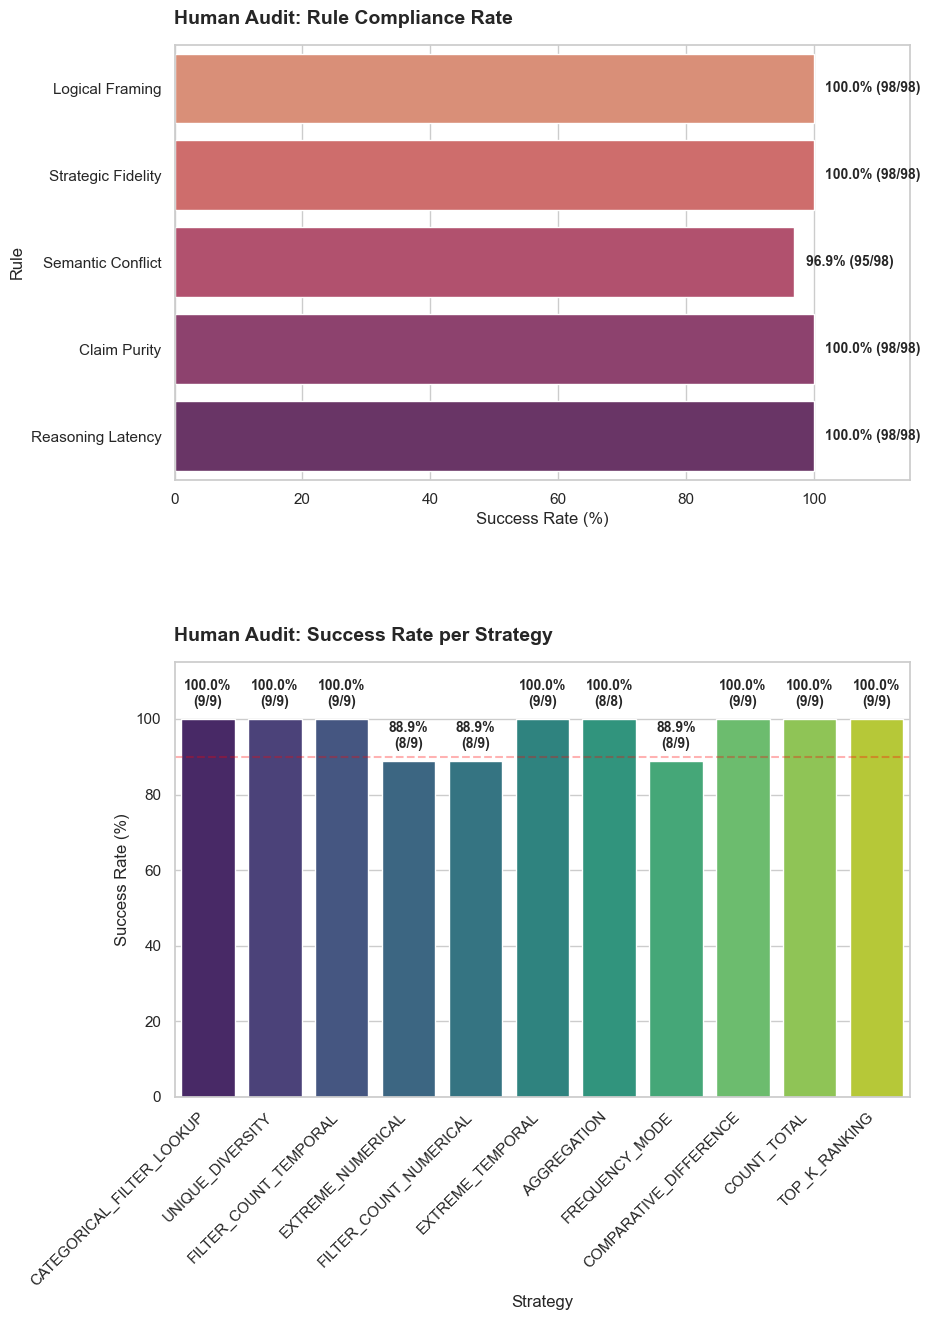

In [562]:
dataset_tagger.plot_results()

# Model-Based Vaidation Process:
This section of the notebook executes an automated Epistemic Audit using Gemini 3.1 Pro as the "Gold Standard" validator.

Auditing Knowledge Maze:   0%|          | 0/151 [00:00<?, ?it/s]

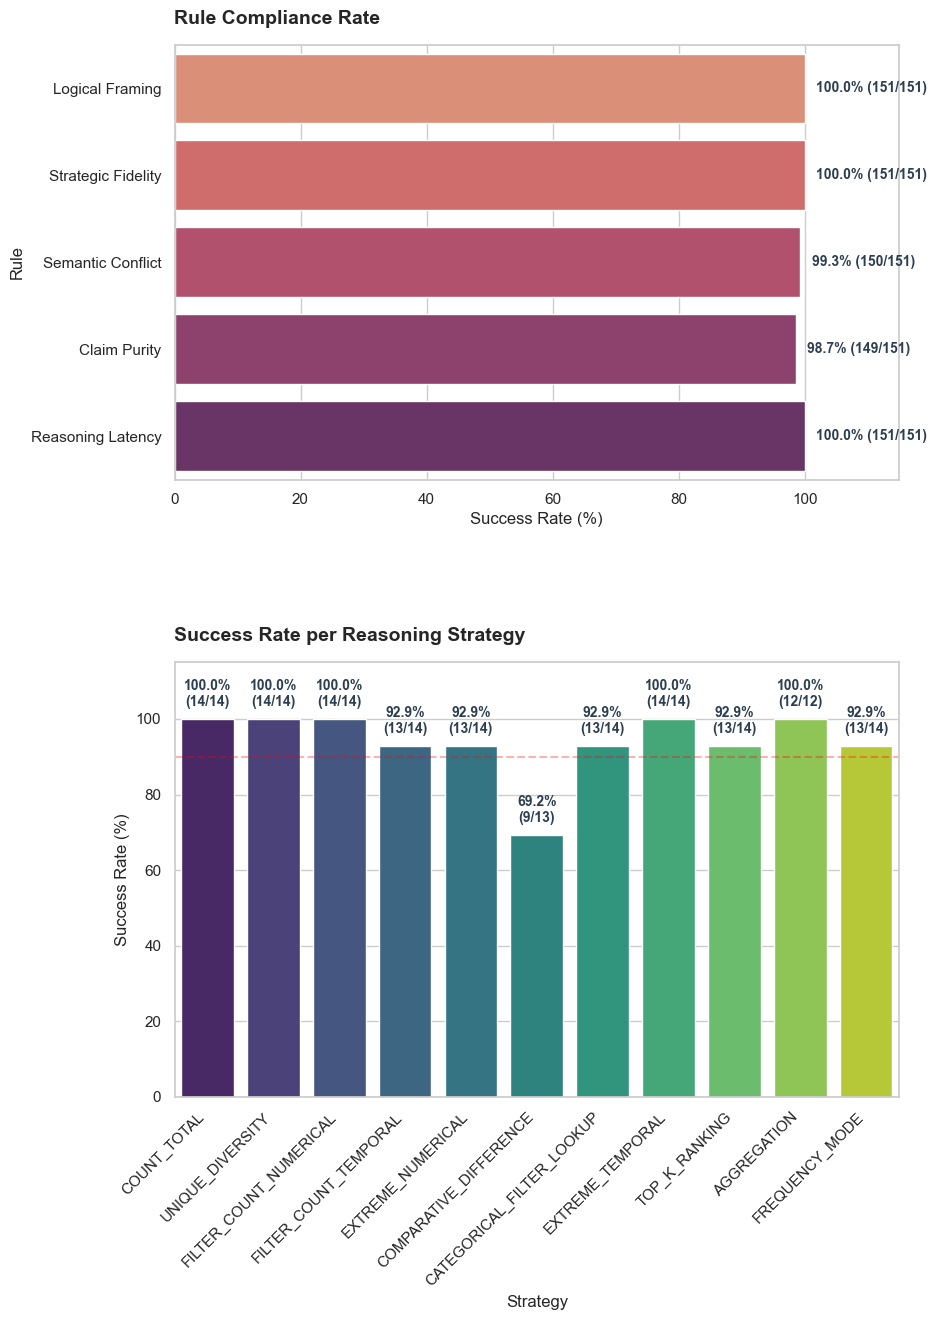

In [361]:
annotator = KnowledgeMazeAnnotator(model_name="google/gemini-3.1-pro-preview")
results, report = await annotator.annotate_dataset(question_dataset_small, paragraph_dataset, strategy_defs, limit=len(question_dataset_small))

# Human-Model Agreement Score:

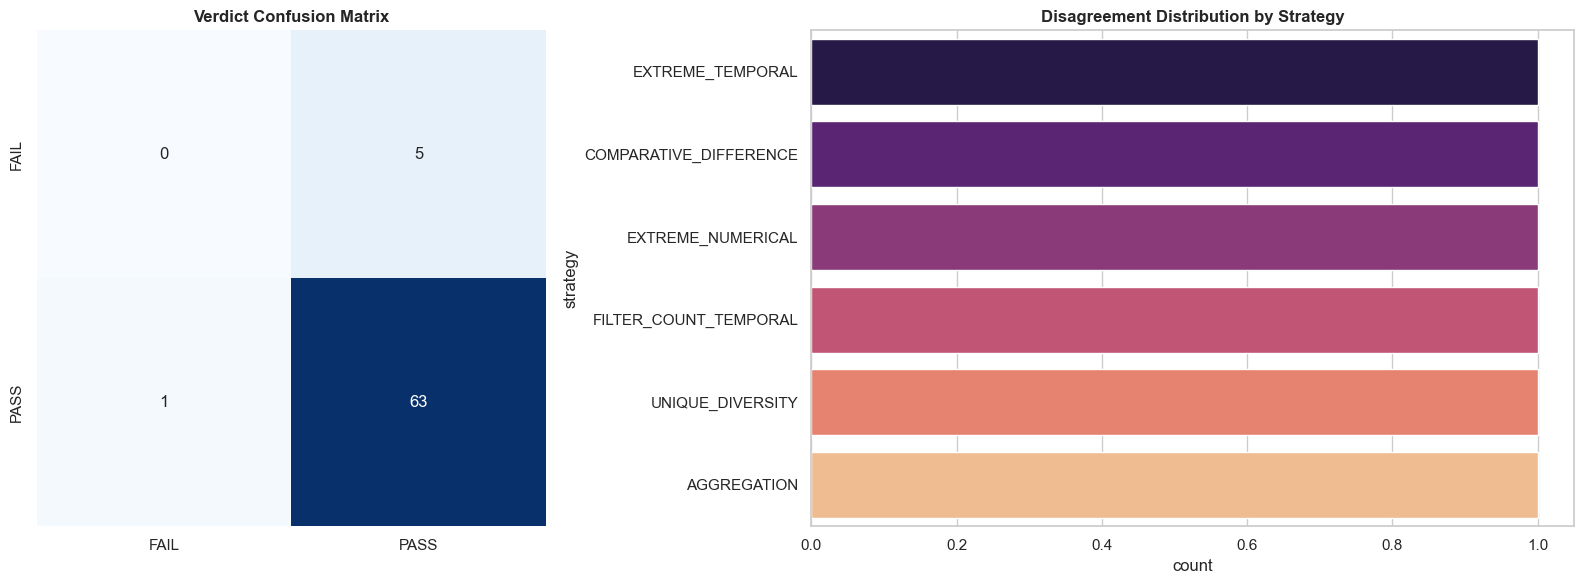

In [414]:
human_snnotation = load_json(os.path.join(REPO_PATH, "notebooks/paragraph_audit_progress.json"))
model_annotation = results
df_comparison = calculate_auditor_agreement(model_annotation, human_snnotation)

# Inter-Annotator Agreement Score:

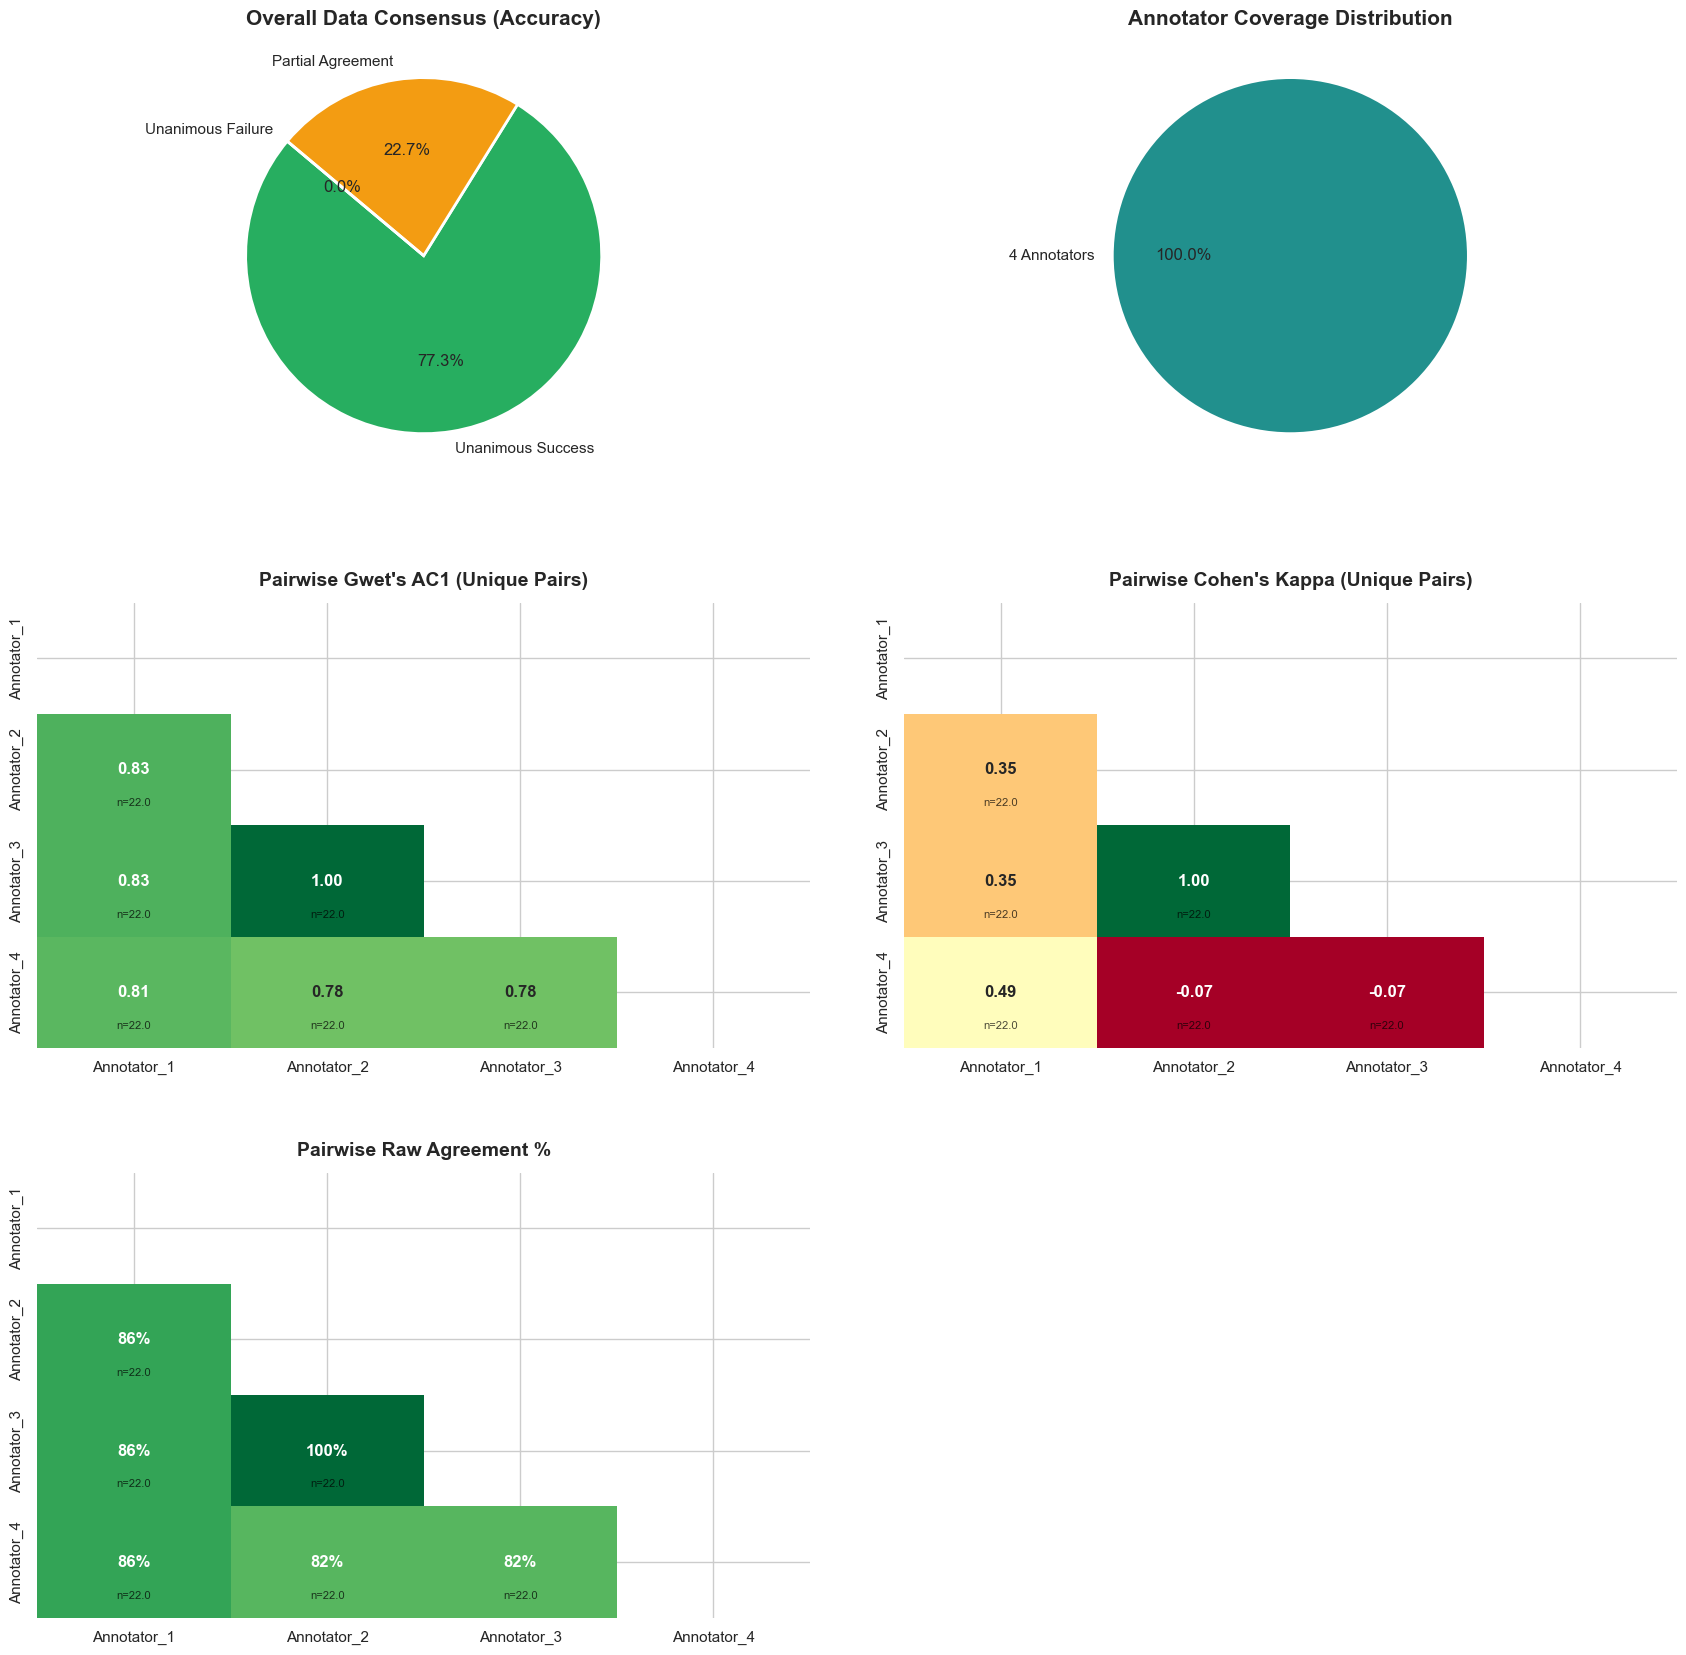

✅ Analysis Complete. Disputed IDs found: 5


In [493]:
files = [os.path.join(REPO_PATH, "knowledge_maze/create_dataset/data_annotation/annotated_data/paragraph_audit_progress_1.json"), 
         os.path.join(REPO_PATH, "knowledge_maze/create_dataset/data_annotation/annotated_data/paragraph_audit_progress_2.json"), 
         os.path.join(REPO_PATH, "knowledge_maze/create_dataset/data_annotation/annotated_data/paragraph_audit_progress_3.json"), 
         os.path.join(REPO_PATH, "knowledge_maze/create_dataset/data_annotation/annotated_data/paragraph_audit_progress_4.json")]
df, conflict_ids = calculate_human_agreement(files)

In [494]:
import pandas as pd
import os
import re

def create_annotator_matrix(files):
    all_rows = []
    
    for f in files:
        # 1. Extract annotator name from filename (e.g., 'data_john.json' -> 'john')
        # This assumes the name is the last part of the filename before the extension
        annotator_name = os.path.basename(f).replace('.json', '').split('_')[-1]
        
        data = load_json(f)
        for entry in data:
            all_rows.append({
                'ID': entry['ID'],
                'Annotator': annotator_name,
                'Verdict': entry['status']
            })
    
    # 2. Create a long-form DataFrame
    df_long = pd.DataFrame(all_rows)
    
    # 3. Pivot to wide-form
    # Rows = IDs, Columns = Annotators, Values = Verdicts
    matrix_df = df_long.pivot(index='ID', columns='Annotator', values='Verdict')
    
    return matrix_df

# Usage
# files = ["results_ann1.json", "results_ann2.json", ...]
verdict_matrix = create_annotator_matrix(files)

# 2. Updated styling for "One-Line IDs"
styled_matrix = (
    verdict_matrix.style
    .apply(highlight_disagreements, axis=1)
    .set_table_styles([
        # Table overall setup
        {'selector': '', 'props': [
            ('table-layout', 'auto'), 
            ('width', '400px'),
            ('margin-left', '0'),
            ('margin-right', 'auto')
        ]},
        
        # Row Headers (The IDs) - THE FIX IS HERE
        {'selector': 'th.row_heading', 'props': [
            ('width', '300px'),           # Manually set your preferred width here
            ('min-width', '350px'),       # Ensure it doesn't shrink
            ('white-space', 'nowrap'),    # CRITICAL: Forces the ID into one row
            ('text-align', 'left'), 
            ('font-family', 'monospace'),
            ('padding', '0 15px')
        ]},

        # ID Column Header (index name)
        {'selector': 'th.index_name', 'props': [
            ('text-align', 'center'),
            ('padding', '10px')
        ]},
        
        # Column Headers (The Names)
        {'selector': 'th.col_heading', 'props': [
            ('text-align', 'center'),
            ('min-width', '100px'),
            ('padding', '10px')
        ]},
        
        # Data Cells
        {'selector': 'td', 'props': [
            ('text-align', 'center'),
            ('white-space', 'nowrap'),
            ('padding', '8px 15px')
        ]}
    ])
)

display(styled_matrix)

Annotator,1,2,3,4
ID,,,,
08010ee0-0c53-44f3-b8f3-4e7e7fea9fd7,success,success,success,success
0b82a624-8539-4edf-b480-87a85aacc081,success,success,success,success
2a9e5046-6e7f-4001-b17b-4b1443276ded,success,success,success,success
2c3e7b7b-557a-4ded-8976-1a6783abee5f,success,success,success,success
31535314-f0fd-4c47-ab5a-ec5196976b7f,success,success,success,success
505887d2-a9e4-433c-9926-4d984b76b4c8,success,success,success,success
55a2b40e-53cf-4edb-8cb7-2e0e3d3f6ccd,success,success,success,success
561ba6d8-9d38-4c28-83e1-d2245c27828c,success,success,success,success
79a77dd2-e05e-41b1-9644-d2b5a040474b,success,success,success,success
